<a href="https://colab.research.google.com/github/raphomungi/AI-for-Machine-Learning/blob/main/Unsupervised_Machine_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [18]:
import pandas as pd, numpy as np

url = "hf://datasets/samyuktha01/Indian_Railway_maintance/indian_railway_predictive_maintenance_100k.csv"
df = pd.read_csv(url)
df.head(3)

,train_id,region,season,train_type,train_age_years,average_speed_kmph,distance_travelled_km,track_temperature_c,rail_wear_mm,track_vibration_level,...,load_factor_percent,daily_trips,delay_minutes,last_maintenance_days,inspection_score,sensor_health_index,failure_type,maintenance_required,failure_severity,risk_score
0,1,Central Railway,Winter,Freight,18,93.911426,1088075,30.385539,11.267384,5.017916,...,59.221583,16,10.678221,75.0,81.614028,48.229938,NaN,0,NaN,66.621259
1,2,South Central Railway,Monsoon,Freight,3,83.985560,872233,39.700773,10.452440,NaN,...,62.512150,20,12.612107,182.0,94.538873,56.726790,NaN,0,NaN,59.477828
2,3,Southern Railway,Monsoon,Express,25,70.446432,1215080,54.346229,10.794243,5.043626,...,59.385796,20,8.537663,161.0,82.556458,73.183802,NaN,0,NaN,59.666196


In [19]:
from sklearn.preprocessing import StandardScaler

features = ["inspection_score", "sensor_health_index"]
X_clean = df[features].dropna()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_clean)

print("Original data shape:", df.shape)
print("Scaled data shape:", X_scaled.shape)

Original data shape: (100300, 35)
Scaled data shape: (100300, 2)


In [22]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

ks = range(2, 7)
inertia, silhouette = [], []
for k in ks:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    inertia.append(model.inertia_)
    silhouette.append(silhouette_score(X_scaled, labels))

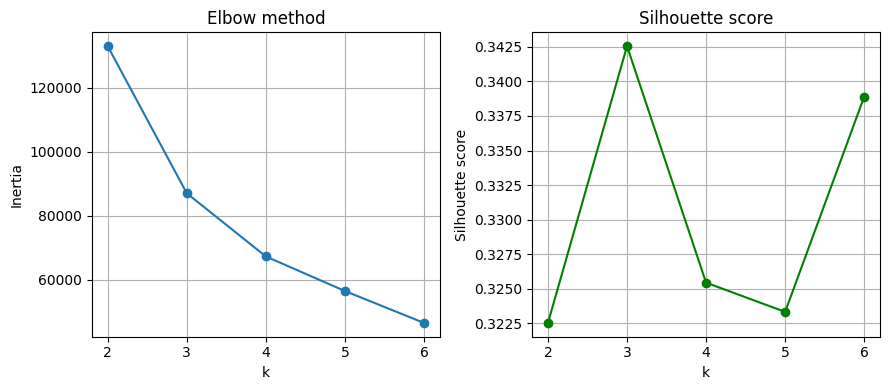

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].plot(ks, inertia, "o-"); ax[0].set_title("Elbow method"); ax[0].set_xlabel("k"); ax[0].set_ylabel("Inertia"); ax[0].grid(True)
ax[1].plot(ks, silhouette, "o-", color="green"); ax[1].set_title("Silhouette score"); ax[1].set_xlabel("k"); ax[1].set_ylabel("Silhouette score"); ax[1].grid(True)
plt.tight_layout()
plt.show()

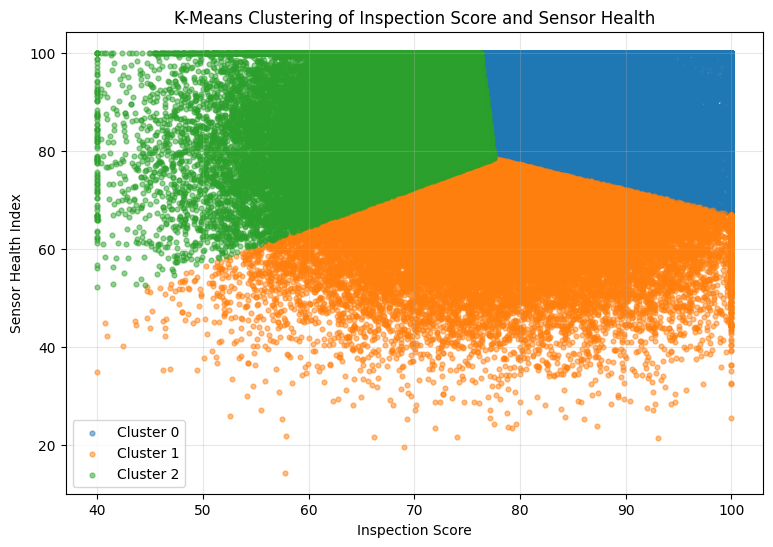

In [27]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(X_scaled)

clustered_data = X_clean.copy()
clustered_data["cluster"] = cluster_labels

plt.figure(figsize=(9, 6))

for cluster_id in sorted(clustered_data["cluster"].unique()):
    cluster_data = clustered_data[clustered_data["cluster"] == cluster_id]
    plt.scatter(cluster_data["inspection_score"], cluster_data["sensor_health_index"],
        label=f"Cluster {cluster_id}", alpha=0.5, s=12)

plt.xlabel("Inspection Score"), plt.ylabel("Sensor Health Index"), plt.title("K-Means Clustering of Inspection Score and Sensor Health")
plt.legend(), plt.grid(True, alpha=0.3)
plt.show()


In [31]:

# Summary of each cluster
cluster_summary = clustered_data.groupby("cluster").agg(
   Count=("inspection_score", "size"),
    Mean_Inspection_Score=("inspection_score", "mean"),
    Mean_Sensor_Health=("sensor_health_index", "mean"),

).round(2)

print(cluster_summary)


         Count  Mean_Inspection_Score  Mean_Sensor_Health
cluster                                                  
0        35364                  87.38               87.43
1        31694                  78.95               63.77
2        33242                  66.72               85.60


### Cluster 0 — High inspection score and high sensor health
- Observations: 35,364 (35.3%)
- Mean inspection score: 87.38
- Mean sensor health index: 87.43
Interpretation: This group has high average values for both features. If higher scores represent better condition, these observations may represent rolling stock with relatively good inspection results and sensor health.
### Cluster 1 — Moderate inspection score and lower sensor health
- Observations: 31,694 (31.6%)
- Mean inspection score: 78.95
- Mean sensor health index: 63.77
Interpretation: This group has the lowest average sensor health index, while its average inspection score is between those of the other two clusters. It may be useful to investigate sensor condition and whether the sensor readings agree with physical inspection findings.
### Cluster 2 — Lower inspection score and high sensor health
- Observations: 33,242 (33.1%)
- Mean inspection score: 66.72
- Mean sensor health index: 85.60
Interpretation: This group has the lowest average inspection score but a relatively high sensor health index. It may represent observations where physical inspection results are less favourable despite relatively healthy sensors. Further investigation could help identify possible maintenance concerns that sensor health alone may not reveal.

# Discovering Patterns in Rolling Stock Data Using K-Means Clustering

## 1. Feature Selection and Preparation

The `inspection_score` and `sensor_health_index` features were selected to investigate patterns in rolling stock inspection results and sensor health. The dataset contained 100,300 observations, with no missing values in either feature. The selected features were standardized using `StandardScaler` before clustering to ensure that differences in their numerical scales did not disproportionately influence the distance calculations.

## 2. Clustering Method and Selection of the Number of Clusters

K-Means clustering was applied to the standardized data. Different cluster counts, from two to six, were evaluated using the Elbow Method and Silhouette Score. Three clusters were selected because the inertia plot showed a substantial reduction between two and three clusters, followed by smaller improvements, while the highest Silhouette Score of 0.3425 was obtained at three clusters.

## 3. Characteristics of the Identified Groups

**Cluster 0:** This group contained 35,364 observations (35.3%). It had a mean inspection score of 87.38 and a mean sensor health index of 87.43, indicating relatively high values for both features.

**Cluster 1:** This group contained 31,694 observations (31.6%). Its mean inspection score was 78.95, while its mean sensor health index was 63.77. This group had the lowest average sensor health index, making it a useful candidate for further investigation of sensor condition.

**Cluster 2:** This group contained 33,242 observations (33.1%). It had a mean inspection score of 66.72 and a mean sensor health index of 85.60. The difference between these averages suggests that inspection results and sensor health may provide complementary information about rolling stock condition.

## 4. Conclusion

The K-Means model identified three groups with different combinations of inspection scores and sensor health indices. The results demonstrate how clustering can reveal patterns in rolling stock data without predefined group labels. These groups may support further investigation of maintenance priorities, particularly where inspection results and sensor health differ. However, the clusters should not be treated as confirmed maintenance-risk categories until the feature definitions and their relationship to actual failures and maintenance outcomes have been validated.